# **Assignment 4**


**Anja Pijak**  
ap72051@student.uni-lj.si


In [21]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score 

#### Data preparation


In [ ]:
df = pd.read_csv("datasets/House_Price.csv")

df.head()


,price,crime_rate,resid_area,air_qual,room_num,age,dist1,dist2,dist3,dist4,teachers,poor_prop,airport,n_hos_beds,n_hot_rooms,waterbody,rainfall,bus_ter,parks
0,24.0,0.00632,32.31,0.538,6.575,65.2,4.35,3.81,4.18,4.01,24.7,4.98,YES,5.480,11.1920,River,23,YES,0.049347
1,21.6,0.02731,37.07,0.469,6.421,78.9,4.99,4.70,5.12,5.06,22.2,9.14,NO,7.332,12.1728,Lake,42,YES,0.046146
2,34.7,0.02729,37.07,0.469,7.185,61.1,5.03,4.86,5.01,4.97,22.2,4.03,NO,7.394,101.1200,NaN,38,YES,0.045764
3,33.4,0.03237,32.18,0.458,6.998,45.8,6.21,5.93,6.16,5.96,21.3,2.94,YES,9.268,11.2672,Lake,45,YES,0.047151
4,36.2,0.06905,32.18,0.458,7.147,54.2,6.16,5.86,6.37,5.86,21.3,5.33,NO,8.824,11.2896,Lake,55,YES,0.039474


In [ ]:
X = df.loc[:, df.columns != 'price'] # attributes
y = df['price'] # target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)


# Fill missing values for all columns except string columns
columns_to_fill = X_train.columns.difference(["waterbody", "bus_ter", "airport"])

X_train[columns_to_fill] = X_train[columns_to_fill].fillna(X_train[columns_to_fill].mean())
X_test[columns_to_fill] = X_test[columns_to_fill].fillna(X_train[columns_to_fill].mean()) 

# Encode categorical variables (because for every it can be 1 of 2 categories)
X_train['waterbody'] = X_train['waterbody'].apply(lambda x: 1 if x == "River" else 0)
X_test['waterbody'] = X_test['waterbody'].apply(lambda x: 1 if x == "River" else 0)

X_train['bus_ter'] = X_train['bus_ter'].apply(lambda x: 1 if x == "YES" else 0)
X_test['bus_ter'] = X_test['bus_ter'].apply(lambda x: 1 if x == "YES" else 0)

X_train['airport'] = X_train['airport'].apply(lambda x: 1 if x == "YES" else 0)
X_test['airport'] = X_test['airport'].apply(lambda x: 1 if x == "YES" else 0)



In [ ]:
class RegressionTree:
    def __init__(self, max_depth=3, min_samples_split=2):
        self.max_depth = max_depth  
        self.min_samples_split = min_samples_split 
        self.tree = None  

    def _calculate_rss(self, left_y, right_y):
        # Method to calculate residual sum of squares (RSS)
        left_rss = np.sum((left_y - np.mean(left_y)) ** 2) 
        right_rss = np.sum((right_y - np.mean(right_y)) ** 2)
        return left_rss + right_rss


    def _grow_tree(self, X, y, depth=0):
        # Recursive method to grow the tree
        n_samples, n_features = X.shape
        if n_samples < self.min_samples_split or (self.max_depth is not None and depth >= self.max_depth):
            # If stopping criteria is met, return leaf node with the mean value of y
            leaf_value = np.mean(y)
            return {"leaf": leaf_value}

        # Find the best split
        best_split = self._find_best_split(X, y)
        # Recursively grow the left and right subtrees
        left_tree = self._grow_tree(X[best_split["left_indices"]], y[best_split["left_indices"]], depth + 1)
        right_tree = self._grow_tree(X[best_split["right_indices"]], y[best_split["right_indices"]], depth + 1)
        return {"feature": best_split["feature"], "threshold": best_split["threshold"], "left": left_tree, "right": right_tree}

    def _find_best_split(self, X, y):
        # Method to find the best split for the tree
        n_samples, n_features = X.shape
        best_rss = float("inf")
        best_split = {}

        for feature_index in range(n_features):
            thresholds = np.unique(X[:, feature_index])
            for threshold in thresholds:
                left_indices = X[:, feature_index] <= threshold
                right_indices = X[:, feature_index] > threshold
                
                # Avoid empty splits
                if np.sum(left_indices) == 0 or np.sum(right_indices) == 0:
                    continue

                # Calculate RSS for the split
                rss = self._calculate_rss(y[left_indices], y[right_indices])
                if rss < best_rss:
                    # Update the best split if the current one is better
                    best_rss = rss
                    best_split = {"feature": feature_index, "threshold": threshold, "left_indices": left_indices, "right_indices": right_indices}
        return best_split
    
    def fit(self, X, y):
        # Fit the tree to the data
        self.tree = self._grow_tree(X, y)

    def predict(self, X):
        # Predict method to make predictions on new data
        return np.array([self._predict(sample, self.tree) for sample in X])

    def _predict(self, sample, tree):
        # Recursive method to make a prediction for a single sample
        if "leaf" in tree:
            return tree["leaf"]
        feature_index = tree["feature"]
        threshold = tree["threshold"]
        if sample[feature_index] <= threshold:
            return self._predict(sample, tree["left"])
        else:
            return self._predict(sample, tree["right"])



Checking if it works before cross validation

In [ ]:

tree = RegressionTree(max_depth=4, min_samples_split=10)
tree.fit(X_train.values, y_train.values)  # Ensure using numpy arrays since my class is using those

y_pred = tree.predict(X_test.values)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print(mae, mse)


2.7090087970863514 12.28399143741182


Cross validation for both, my implementation and scikit implementation

In [ ]:
# Perform cross-validation with different stopping criteria for both models
kf = KFold(n_splits=5, shuffle=True, random_state=42)
max_depth_values = [3, 4, 5, 6, 7, 9, 11, 15]
min_samples_split_values = [2, 5, 10]

results = []

for max_depth in max_depth_values:
    for min_samples_split in min_samples_split_values:
        mae_scores_custom = []
        mae_scores_sklearn = []

        for train_index, val_index in kf.split(X_train):
            X_train_cv, X_val_cv = X_train.values[train_index], X_train.values[val_index]
            y_train_cv, y_val_cv = y_train.values[train_index], y_train.values[val_index]

            # My regression tree
            custom_tree = RegressionTree(max_depth=max_depth, min_samples_split=min_samples_split)
            custom_tree.fit(X_train_cv, y_train_cv)
            y_pred_cv_custom = custom_tree.predict(X_val_cv)
            mae_custom = mean_absolute_error(y_val_cv, y_pred_cv_custom)
            mae_scores_custom.append(mae_custom)

            # Scikit-learn regression tree
            sklearn_tree = DecisionTreeRegressor(max_depth=max_depth, min_samples_split=min_samples_split)
            sklearn_tree.fit(X_train_cv, y_train_cv)
            y_pred_cv_sklearn = sklearn_tree.predict(X_val_cv)
            mae_sklearn = mean_absolute_error(y_val_cv, y_pred_cv_sklearn)
            mae_scores_sklearn.append(mae_sklearn)

        mean_mae_custom = np.mean(mae_scores_custom)
        mean_mae_sklearn = np.mean(mae_scores_sklearn)
        results.append({
            "max_depth": max_depth,
            "min_samples_split": min_samples_split,
            "MAE (Custom)": mean_mae_custom,
            "MAE (scikit-learn)": mean_mae_sklearn
        })




Tabular representation of results

In [ ]:
print(tabulate(results, headers="keys", tablefmt="grid"))


+-------------+---------------------+----------------+----------------------+
|   max_depth |   min_samples_split |   MAE (Custom) |   MAE (scikit-learn) |
+=============+=====================+================+======================+
|           3 |                   2 |        3.54302 |              3.57356 |
+-------------+---------------------+----------------+----------------------+
|           3 |                   5 |        3.54302 |              3.56655 |
+-------------+---------------------+----------------+----------------------+
|           3 |                  10 |        3.54302 |              3.52503 |
+-------------+---------------------+----------------+----------------------+
|           4 |                   2 |        3.26811 |              3.11896 |
+-------------+---------------------+----------------+----------------------+
|           4 |                   5 |        3.2905  |              3.15149 |
+-------------+---------------------+----------------+----------

Representation as a plot

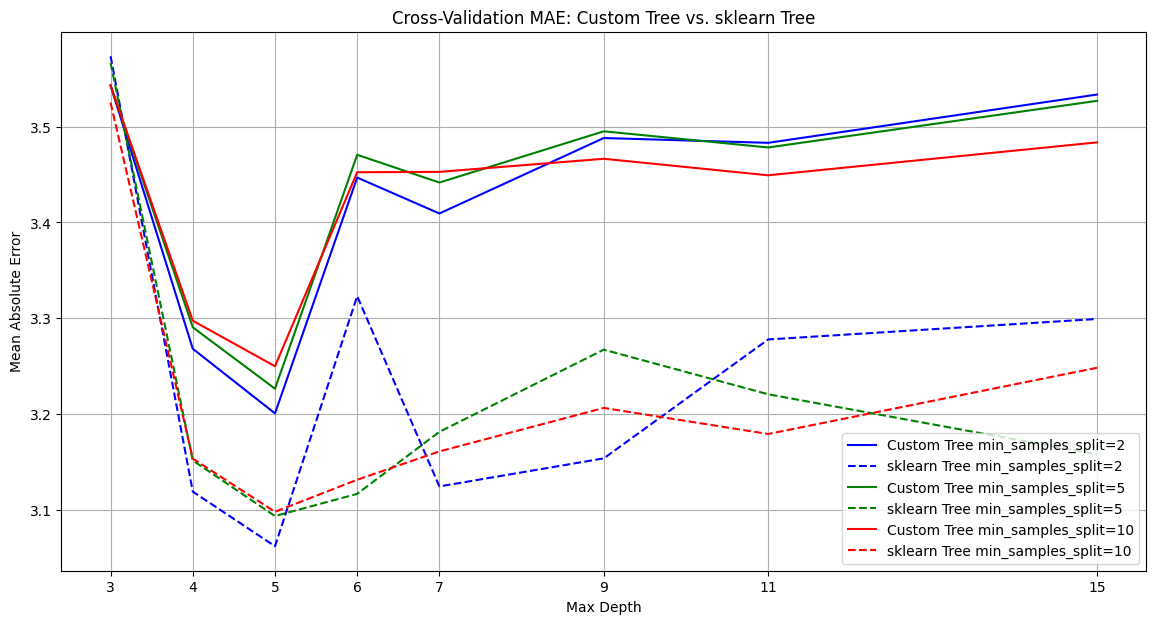

In [ ]:
results_df = pd.DataFrame(results)

# Plot the results
plt.figure(figsize=(14, 7))
colors = ['b', 'g', 'r', 'c', 'm', 'y', 'k']
for i, min_samples_split in enumerate(min_samples_split_values):
    subset = results_df[results_df['min_samples_split'] == min_samples_split]
    plt.plot(subset['max_depth'], subset['MAE (Custom)'], color=colors[i], linewidth=1.5, label=f'Custom Tree min_samples_split={min_samples_split}')
    plt.plot(subset['max_depth'], subset['MAE (scikit-learn)'], color=colors[i], linestyle='--', linewidth=1.5, label=f'sklearn Tree min_samples_split={min_samples_split}')

plt.xlabel('Max Depth')
plt.ylabel('Mean Absolute Error')
plt.title('Cross-Validation MAE: Custom Tree vs. sklearn Tree')
plt.legend()
plt.grid(True)
plt.xticks([3, 4, 5, 6, 7, 9, 11, 15]) 
plt.show()



I didn't see any examples of overfitting with neither, my implementation, nor scikit implementation. The MAE remains between 3.0 and 3.6 for each stopping criteria. However, we see that scikit implemntation gives better results then mine. 

We can see some optimal stopping criteria from the plot:
- max depth of 5 with either min_samples_split (however 10 is optimal for both implementations)
- for scikit implementation, best performance is with height 7 and min_samples_split 5